In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [3]:
data = pd.read_csv('insurance.csv')
# here, output variable is numeric or continous

In [4]:
data.head()


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


# EDA

### 1) VIEWING THE DATA


In [5]:
data.shape

(1338, 7)

In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [7]:
data.head()


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [8]:
data.tail()

,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.5483
1334,18,female,31.92,0,no,northeast,2205.9808
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603


### 2) SUMMARY STATS

In [9]:
data.describe()


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


### 3) MISSING VALUE ANALYSIS

In [10]:
data.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

### 4) VISUALISATIONS

In [11]:
data.columns


Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')

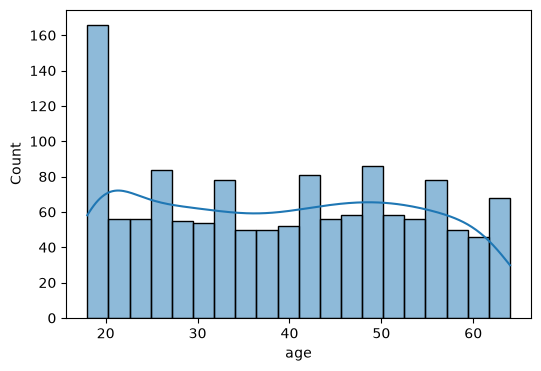

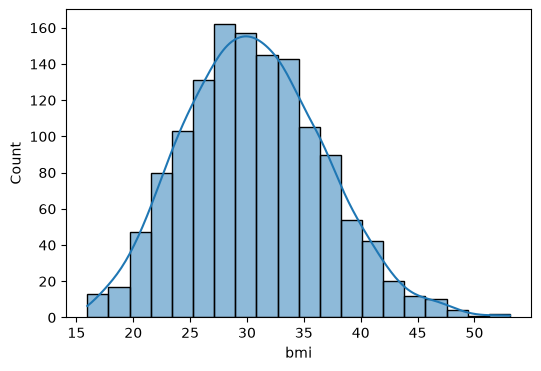

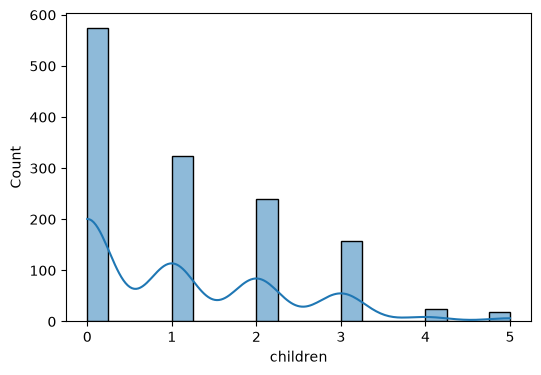

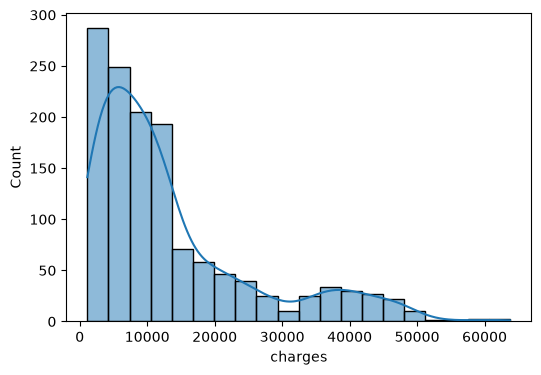

In [12]:
numeric_col = ['age', 'bmi', 'children', 'charges']
for col in numeric_col:
    plt.figure(figsize = (6,4) )
    sns.histplot(data[col], kde = True, bins = 20)

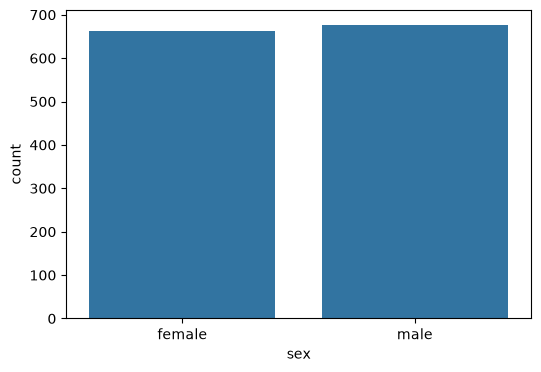

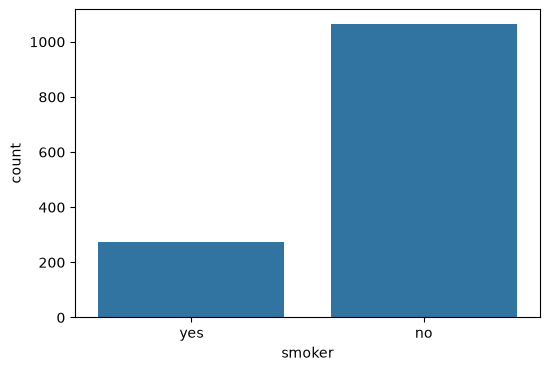

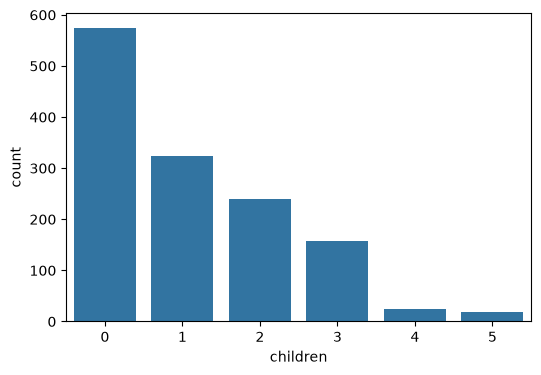

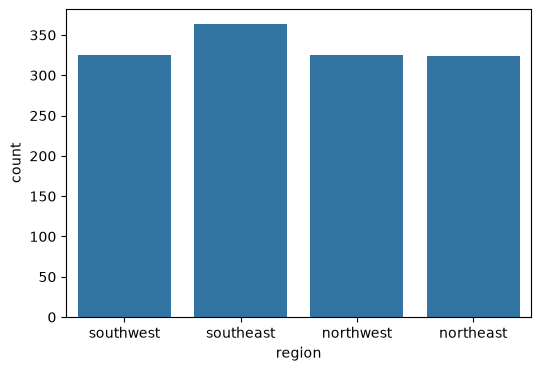

In [13]:
for col in ['sex', 'smoker', 'children', 'region']:
    plt.figure(figsize = (6,4) )                 # this creates a canvas kinda for every graph. or else all graph will be shown on same canvas
    sns.countplot(x = data[col])

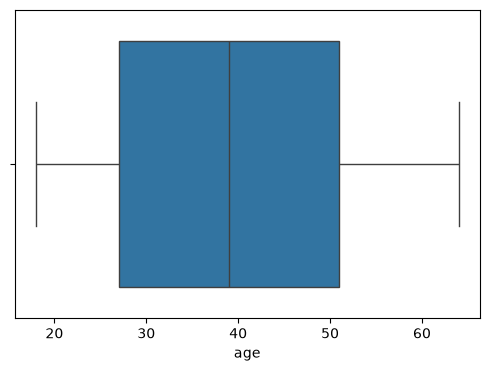

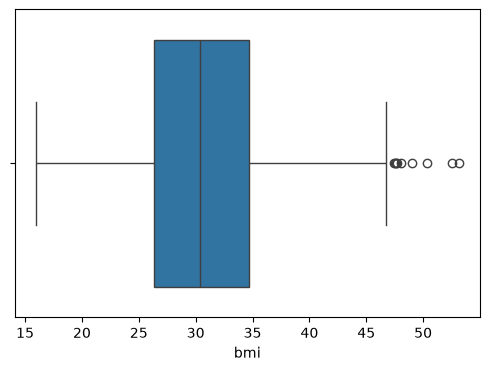

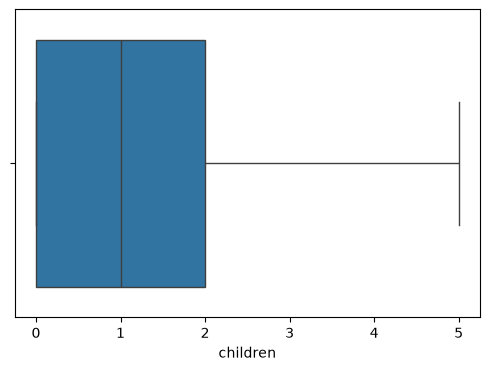

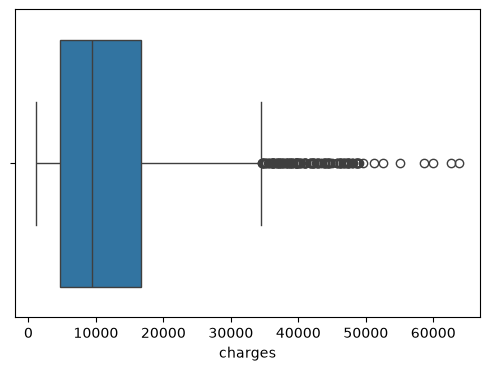

In [14]:
for col in numeric_col:
    plt.figure(figsize = (6,4) )
    sns.boxplot(x = data[col])

<Axes: >

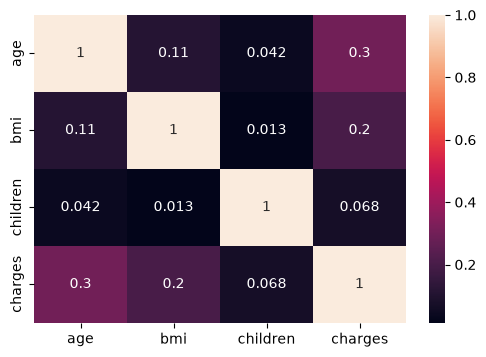

In [15]:
plt.figure(figsize = (6,4))
sns.heatmap(data.corr(numeric_only = True), annot = True) 

# DATA CLEANING AND PREPROCESSING

### 1) DUPLICATES

In [16]:
data_cleaned = data.copy()
data_cleaned.shape


(1338, 7)

In [17]:
data_cleaned.drop_duplicates(inplace = True)
data_cleaned.shape

(1337, 7)

### 2) NULL VALUES

In [18]:
data_cleaned.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

### 3) ENCODING CATEGORIAL COLUMNS TO 0 AND 1

In [19]:
data_cleaned['sex'].value_counts()

sex
male      675
female    662
Name: count, dtype: int64

In [20]:
data_cleaned['sex'] = data_cleaned['sex'].map( {'male':0, 'female':1} )     # run this a single time only

In [21]:
data_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,yes,southwest,16884.92400
1,18,0,33.770,1,no,southeast,1725.55230
2,28,0,33.000,3,no,southeast,4449.46200
3,33,0,22.705,0,no,northwest,21984.47061
4,32,0,28.880,0,no,northwest,3866.85520


In [22]:
data_cleaned['smoker'].value_counts()

smoker
no     1063
yes     274
Name: count, dtype: int64

In [23]:
data_cleaned['smoker'] = data_cleaned['smoker'].map(  { 'no':0 , 'yes':1}  ) 

In [24]:
data_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


In [25]:
data_cleaned.rename(columns = {
    'sex' : 'is_female',
    'smoker' : 'is_smoker'
}, inplace = True )

In [26]:
data_cleaned.head()

,age,is_female,bmi,children,is_smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


### 3.1) 1 hot encoding

In [27]:
data_cleaned = pd.get_dummies(data_cleaned, columns = ['region'], drop_first = True) # drop_first so that we drop our 'region' coln

In [28]:
data_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,False,False,True
1,18,0,33.770,1,0,1725.55230,False,True,False
2,28,0,33.000,3,0,4449.46200,False,True,False
3,33,0,22.705,0,0,21984.47061,True,False,False
4,32,0,28.880,0,0,3866.85520,True,False,False


In [29]:
data_cleaned = data_cleaned.astype(int)    # this converts false/true to 0/1
data_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest
0,19,1,27,0,1,16884,0,0,1
1,18,0,33,1,0,1725,0,1,0
2,28,0,33,3,0,4449,0,1,0
3,33,0,22,0,0,21984,1,0,0
4,32,0,28,0,0,3866,1,0,0


# Feature Engineering

<Axes: xlabel='bmi', ylabel='Count'>

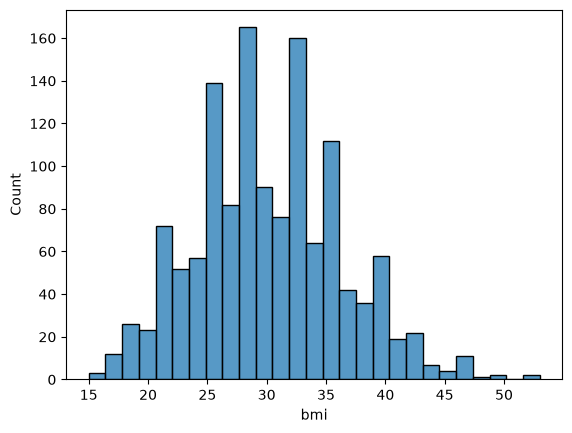

In [30]:
sns.histplot(data_cleaned['bmi'])

In [31]:
data_cleaned['bmi_category'] = pd.cut(
    data_cleaned['bmi'],
    bins = [0,18.5, 24.9, 29.9, float('inf')],
    labels = ["underweight", "normal", "overweight", "obese"] )

In [32]:
data_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category
0,19,1,27,0,1,16884,0,0,1,overweight
1,18,0,33,1,0,1725,0,1,0,obese
2,28,0,33,3,0,4449,0,1,0,obese
3,33,0,22,0,0,21984,1,0,0,normal
4,32,0,28,0,0,3866,1,0,0,overweight


In [33]:
data_cleaned = pd.get_dummies(data_cleaned, columns = ['bmi_category'], drop_first = True)
# 1 hot encoding done again

In [34]:
data_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_normal,bmi_category_overweight,bmi_category_obese
0,19,1,27,0,1,16884,0,0,1,False,True,False
1,18,0,33,1,0,1725,0,1,0,False,False,True
2,28,0,33,3,0,4449,0,1,0,False,False,True
3,33,0,22,0,0,21984,1,0,0,True,False,False
4,32,0,28,0,0,3866,1,0,0,False,True,False


In [35]:
data_cleaned = data_cleaned.astype(int)
data_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_normal,bmi_category_overweight,bmi_category_obese
0,19,1,27,0,1,16884,0,0,1,0,1,0
1,18,0,33,1,0,1725,0,1,0,0,0,1
2,28,0,33,3,0,4449,0,1,0,0,0,1
3,33,0,22,0,0,21984,1,0,0,1,0,0
4,32,0,28,0,0,3866,1,0,0,0,1,0


# Feature Scaling (part of feature engineering)

In [36]:
from sklearn.preprocessing import StandardScaler
cols = ['age', 'bmi', 'children']
# these are the input variables which are not in 0 & 1
scaler = StandardScaler()
data_cleaned[cols] = scaler.fit_transform(data_cleaned[cols])
data_cleaned.head()
# charges are output variables which we dont touch

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_normal,bmi_category_overweight,bmi_category_obese
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0,1,0,1,0
1,-1.511647,0,0.462463,-0.079442,0,1725,0,1,0,0,0,1
2,-0.799350,0,0.462463,1.580143,0,4449,0,1,0,0,0,1
3,-0.443201,0,-1.334960,-0.909234,0,21984,1,0,0,1,0,0
4,-0.514431,0,-0.354547,-0.909234,0,3866,1,0,0,0,1,0


# Feature Extraction / Selection

In [37]:
from scipy.stats import pearsonr
# this is PEARSON CORELLATION

# list of features to test against our targest variable
selected_features = ['age', 'is_female', 'bmi', 'children', 'is_smoker', 'region_northwest', 'region_southeast', 'region_southwest', 
                     'bmi_category_normal', 'bmi_category_overweight', 'bmi_category_obese']

In [38]:
correlations = {
    feature : pearsonr(data_cleaned[feature], data_cleaned['charges'])[0]
    for feature in selected_features
}

In [39]:
correlations

{'age': np.float64(0.29830870258771736),
 'is_female': np.float64(-0.05804580933726394),
 'bmi': np.float64(0.1962362929936443),
 'children': np.float64(0.06739024185912061),
 'is_smoker': np.float64(0.7872337542693594),
 'region_northwest': np.float64(-0.03869515161276133),
 'region_southeast': np.float64(0.07357719339126033),
 'region_southwest': np.float64(-0.04363698192991321),
 'bmi_category_normal': np.float64(-0.10404195904728353),
 'bmi_category_overweight': np.float64(-0.12060129307098051),
 'bmi_category_obese': np.float64(0.20034756980289617)}

In [40]:
correlation_df = pd.DataFrame(list(correlations.items()), columns = ['Feature', 'Pearson_Correlation'])
correlation_df.sort_values(by='Pearson_Correlation', ascending= False, inplace = True)
correlation_df

,Feature,Pearson_Correlation
4,is_smoker,0.787234
0,age,0.298309
10,bmi_category_obese,0.200348
2,bmi,0.196236
6,region_southeast,0.073577
3,children,0.067390
5,region_northwest,-0.038695
7,region_southwest,-0.043637
1,is_female,-0.058046
8,bmi_category_normal,-0.104042


# CHI SQUARE TEST

In [41]:
# CREATING 4 BINS FOR CHARGES BECAUSE CHI SQUARE TEST IS USED TO COMPARE
# CATEGORIAL VS CATEGORIAL
data_cleaned['charges_bin'] = pd.qcut(data_cleaned['charges'], q=4, labels =False)
categorial_features = [ 'is_female', 'is_smoker', 'region_northwest', 'region_southeast', 'region_southwest', 
                     'bmi_category_normal', 'bmi_category_overweight', 'bmi_category_obese']
data_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_normal,bmi_category_overweight,bmi_category_obese,charges_bin
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0,1,0,1,0,3
1,-1.511647,0,0.462463,-0.079442,0,1725,0,1,0,0,0,1,0
2,-0.799350,0,0.462463,1.580143,0,4449,0,1,0,0,0,1,0
3,-0.443201,0,-1.334960,-0.909234,0,21984,1,0,0,1,0,0,3
4,-0.514431,0,-0.354547,-0.909234,0,3866,1,0,0,0,1,0,0


In [42]:
from scipy.stats import chi2_contingency
chi_square_results={}
for col in categorial_features:
# Create a contingency table
   contingency_table = pd.crosstab(
    data_cleaned[col], data_cleaned['charges_bin']
    
   )

# Perform Chi-square test
   chi2, p, _, _ = chi2_contingency(contingency_table)
   
   if p < 0.05:
       decision = "Reject Null: keep feature"
   else:
       decision = "Accept Null: reject feature"
   chi_square_results[col] = {
    'chi_2_stat': chi2,
    'p_value': p,
    'Decision': decision}

In [43]:
chi_square_results_df  =  pd.DataFrame( chi_square_results ).T   # .T transposes the dataframe
chi_square_results_df.sort_values(by='p_value', inplace = True)

In [44]:
chi_square_results_df

,chi_2_stat,p_value,Decision
is_smoker,848.219178,0.0,Reject Null: keep feature
region_southeast,15.998167,0.001135,Reject Null: keep feature
is_female,10.258784,0.01649,Reject Null: keep feature
bmi_category_obese,8.515711,0.036473,Reject Null: keep feature
region_southwest,5.091893,0.165191,Accept Null: reject feature
bmi_category_overweight,4.25149,0.235557,Accept Null: reject feature
bmi_category_normal,3.708088,0.29476,Accept Null: reject feature
region_northwest,1.13424,0.768815,Accept Null: reject feature
